# 03 · SoilGrids: o que a incerteza diz sobre o que podemos concluir

O SoilGrids entrega, para cada pixel de 250 m, a média predita e o intervalo de predição de 90% (Q0.05–Q0.95). Este notebook mede **quão largo** é esse intervalo frente à variação espacial da média, e **verifica a camada `uncertainty`** do ISRIC, que decidimos não usar.

In [1]:
import os, sys, json, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ.setdefault("TSI_MODE", "demo")
sys.path.insert(0, str(ROOT / "backend"))
warnings.filterwarnings("ignore")
import numpy as np, rasterio, matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from rasterio.transform import from_origin
from app.core import terrain, dem as demmod, soil as soilmod, zonal, geometry as geom, contours
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": .25})
with rasterio.open(ROOT / "sample_data/demo_dem_glo30.tif") as s:
    DEM, TR = s.read(1), s.transform


In [2]:
import pandas as pd
bbox = (-46.7915, -22.2095, -46.77, -22.1915)
S = soilmod.fetch_demo(bbox); L = S["layers"]
g = lambda p, d, s: L[soilmod.layer_name(p, d, s)]
print("propriedades:", S["props"], "· profundidades:", S["depths"], "· grade:", g("clay", "0-5cm", "mean").shape)

propriedades: ['phh2o', 'soc', 'clay', 'silt', 'sand'] · profundidades: ['0-5cm', '5-15cm', '15-30cm'] · grade: (49, 49)


## 1. Largura do intervalo de 90% × variação espacial da média

Se a **variação espacial** da média predita é minúscula perto da **largura do intervalo**, os mapas de solo dentro de uma propriedade pequena mostram quase só a estrutura do modelo (covariáveis suaves), não diferenças medidas.

In [3]:
rows = []
for p in S["props"]:
    for d in S["depths"]:
        m, lo, hi = g(p, d, "mean"), g(p, d, "q05"), g(p, d, "q95")
        ok = np.isfinite(m)
        rows.append((p, d, np.nanmean(m[ok]), np.nanstd(m[ok]), np.nanmean((hi - lo)[ok]), np.nanstd(m[ok]) / np.nanmean((hi - lo)[ok])))
t = pd.DataFrame(rows, columns=["atributo", "prof.", "média", "desvio espacial da média", "largura média do IC90", "desvio ÷ largura"]).round(3)
print(t.to_string(index=False))
print("\nMediana de (desvio espacial ÷ largura do intervalo):", t["desvio ÷ largura"].median().round(3))

atributo   prof.     média  desvio espacial da média  largura média do IC90  desvio ÷ largura
   phh2o   0-5cm  5.285000                     0.089               2.284000             0.039
   phh2o  5-15cm  5.253000                     0.084               2.173000             0.038
   phh2o 15-30cm  5.265000                     0.079               2.162000             0.037
     soc   0-5cm 30.802999                     3.518              72.804001             0.048
     soc  5-15cm 23.275000                     2.425              51.507999             0.047
     soc 15-30cm 16.158001                     1.572              38.717999             0.041
    clay   0-5cm 34.458000                     1.939              71.089996             0.027
    clay  5-15cm 34.568001                     1.830              70.906998             0.026
    clay 15-30cm 37.520000                     2.034              74.624001             0.027
    silt   0-5cm 22.224001                     2.083        

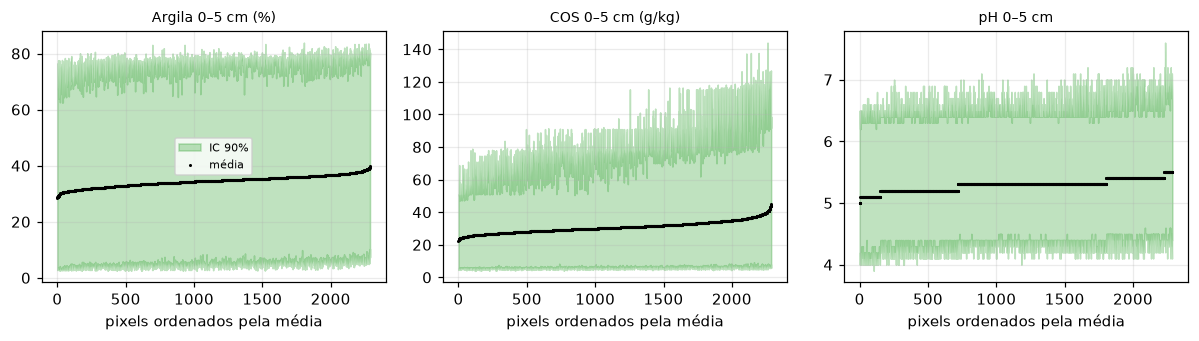

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(11, 3.2))
for a, (p, d, ttl) in zip(ax, [("clay", "0-5cm", "Argila 0–5 cm (%)"), ("soc", "0-5cm", "COS 0–5 cm (g/kg)"), ("phh2o", "0-5cm", "pH 0–5 cm")]):
    m, lo, hi = g(p, d, "mean"), g(p, d, "q05"), g(p, d, "q95")
    ok = np.isfinite(m)
    idx = np.argsort(m[ok])
    mm, ll, hh = m[ok][idx], lo[ok][idx], hi[ok][idx]
    a.fill_between(range(len(mm)), ll, hh, alpha=.3, color="C2", label="IC 90%"); a.plot(mm, "k.", ms=2, label="média"); a.set_title(ttl, fontsize=9); a.set_xlabel("pixels ordenados pela média")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 2. Textura é composicional: soma ≈ 100%

Areia + silte + argila devem somar ~100% (SoilGrids modela a textura como dado composicional). Serve de verificação do **fator de conversão** (g/kg → %).

In [5]:
tot = g("sand", "0-5cm", "mean") + g("silt", "0-5cm", "mean") + g("clay", "0-5cm", "mean")
print("soma textura 0–5 cm: min/méd/máx =", np.nanmin(tot).round(2), np.nanmean(tot).round(2), np.nanmax(tot).round(2))
cls = pd.Series([soilmod.texture_class(c, si, sa) for c, si, sa in zip(g("clay", "0-5cm", "mean").ravel(), g("silt", "0-5cm", "mean").ravel(), g("sand", "0-5cm", "mean").ravel())]).value_counts()
print("\nclasse textural USDA das médias preditas (0–5 cm):\n", cls.to_string())
lo_c, hi_c = np.nanmean(g("clay", "0-5cm", "q05")), np.nanmean(g("clay", "0-5cm", "q95"))
lo_s, hi_s = np.nanmean(g("sand", "0-5cm", "q05")), np.nanmean(g("sand", "0-5cm", "q95"))
print(f"\nLimites médios do IC90 (0–5 cm): argila {lo_c:.1f}–{hi_c:.1f}% · areia {lo_s:.1f}–{hi_s:.1f}% → o intervalo abrange texturas muito diferentes; a classe das médias não é determinada pelos dados.")

soma textura 0–5 cm: min/méd/máx = 99.9 100.0 100.1

classe textural USDA das médias preditas (0–5 cm):
 Franco argiloso          1762
Franco argilo-arenoso     491
Argila arenosa             36

Limites médios do IC90 (0–5 cm): argila 4.8–75.9% · areia 13.8–76.0% → o intervalo abrange texturas muito diferentes; a classe das médias não é determinada pelos dados.


## 3. Resolução: quantos pixels do SoilGrids cabem em cada zona?

In [6]:
gj = json.loads((ROOT / "sample_data/propriedade_demo.geojson").read_text())
shape = g("clay", "0-5cm", "mean").shape
rows = []
for f in gj["features"]:
    G = geom.validate_geometry(f["geometry"]).geometry
    mk, mode = zonal._soil_stat(G, g("clay", "0-5cm", "mean"), S["transform"], shape)
    v = g("clay", "0-5cm", "mean")[mk]
    rows.append((f["properties"]["name"], round(geom.metrics(G)["area_ha"], 1), int(np.isfinite(v).sum()), mode, round(float(np.nanmean(v)), 2)))
print(pd.DataFrame(rows, columns=["zona", "área (ha)", "pixels 250 m", "amostragem", "argila média (%)"]).to_string(index=False))

                      zona  área (ha)  pixels 250 m    amostragem  argila média (%)
Fazenda Demo (ilustrativa)      332.9            40 pixel_centers             37.83
          Talhão A (oeste)      108.0            11 pixel_centers             38.47
            Talhão B (sul)       90.4            12 pixel_centers             37.81
          Talhão C (norte)      117.4            14 pixel_centers             37.54
        Talhão D (pequeno)        1.8             1 pixel_centers             37.00


## 4. Verificação da camada `uncertainty` do ISRIC (precisa de internet)

Uma fonte secundária descreve `uncertainty` como (Q0.95 − Q0.05)/Q0.50. A página oficial de documentação do ISRIC estava indisponível (HTTP 502) durante a construção, então **testamos a definição nos dados**: baixamos a camada `uncertainty` do mesmo recorte e comparamos com a razão calculada.

In [7]:
import rasterio
from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
try:
    tr, h, w = soilmod.grid_for_bbox(bbox)
    url = "/vsicurl/https://files.isric.org/soilgrids/latest/data/clay/clay_0-5cm_uncertainty.vrt"
    with rasterio.open(url) as src:
        print("dtype:", src.dtypes[0], "· nodata declarado:", src.nodata, "· tags:", {k: v for k, v in src.tags().items() if k in ("Description", "Units", "Unit")})
        with WarpedVRT(src, crs="EPSG:4326", transform=tr, width=w, height=h, resampling=Resampling.nearest, nodata=src.nodata) as v:
            u = v.read(1).astype("float64")
    u[u == src.nodata] = np.nan
    q05, q50, q95 = (soilmod._read_layer("clay", "0-5cm", s, tr, h, w) for s in ("q05", "q50", "q95"))
    ratio = (q95 - q05) / q50
    ok = np.isfinite(u) & np.isfinite(ratio)
    print(f"pixels comparáveis: {ok.sum()}")
    print("uncertainty (bruto): P5/P50/P95 =", np.nanpercentile(u[ok], [5, 50, 95]).round(1))
    print("(Q95−Q05)/Q50:        P5/P50/P95 =", np.nanpercentile(ratio[ok], [5, 50, 95]).round(3))
    print("correlação de Pearson:", np.corrcoef(u[ok], ratio[ok])[0, 1].round(3), "· razão mediana uncertainty/ratio:", np.nanmedian(u[ok]/ratio[ok]).round(2))
except Exception as e:
    print("Sem rede/fonte indisponível, verificação PULADA:", repr(e)[:150])

dtype: uint16 · nodata declarado: 65535.0 · tags: {}


pixels comparáveis: 68
uncertainty (bruto): P5/P50/P95 = [20.4 22.  23.6]
(Q95−Q05)/Q50:        P5/P50/P95 = [2.034 2.165 2.352]
correlação de Pearson: 0.955 · razão mediana uncertainty/ratio: 9.98


## Conclusões

- A variação espacial da média predita dentro de uma propriedade é uma **fração pequena** da largura do intervalo de 90%: os mapas mostram estrutura do modelo, não diferenças medidas entre talhões.
- A soma da textura ≈ 100% confirma o fator g/kg → %.
- Talhões de poucos hectares **herdam o pixel** de 250 m; talhões vizinhos podem ter valor idêntico.
- Sobre a camada `uncertainty`: nos 68 pixels comparados, ela é ≈ 10 × (Q0.95 − Q0.05)/Q0.50 (razão mediana 9,98; correlação 0,955; o valor bruto é inteiro, o que explica parte da diferença). Isso é **consistente** com a descrição de fonte secundária (a razão), mas a documentação oficial do ISRIC estava indisponível, então a definição e o fator 10 não estão confirmados. O projeto usa Q0.05/Q0.95, que dão a mesma informação diretamente.
- **Não conclui:** nada sobre fertilidade, adubação ou compactação; isso exige amostragem e análise de solo.